In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [26]:
from sklearn.preprocessing import LabelEncoder, StandardScaler, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
df = pd.read_csv(r"D:\vscode\AI-for-business\Assignments\Customer_Churn\Data_sets\WA_Fn-UseC_-Telco-Customer-Churn.csv")


In [27]:
df.drop('customerID', axis=1, inplace=True)

In [28]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].replace(' ', np.nan), errors='coerce')

In [29]:
num_cols = df.select_dtypes(include=['number']).columns
cat_cols = df.select_dtypes(include=['object']).columns

C:\Users\PC\AppData\Local\Temp\ipykernel_19828\816591484.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object']).columns


In [30]:
df[num_cols] = SimpleImputer(strategy='mean').fit_transform(df[num_cols])
df[cat_cols] = SimpleImputer(strategy='most_frequent').fit_transform(df[cat_cols])

In [31]:
for col in cat_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    encoders[col] = le

In [32]:
corrs = df.corr()['Churn'].drop('Churn')
strong_corr = corrs[abs(corrs) > 0.15]
print("Strong Correlations with Churn (>|0.15|):")
print(strong_corr.sort_values(ascending=False))
print("-" * 50)

top_corr_features = list(strong_corr.index)
X = df[top_corr_features]
y = df['Churn'].astype(int)


Strong Correlations with Churn (>|0.15|):
MonthlyCharges      0.193356
PaperlessBilling    0.191825
SeniorCitizen       0.150889
Partner            -0.150448
Dependents         -0.164221
DeviceProtection   -0.178134
OnlineBackup       -0.195525
TotalCharges       -0.199428
TechSupport        -0.282492
OnlineSecurity     -0.289309
tenure             -0.352229
Contract           -0.396713
Name: Churn, dtype: float64
--------------------------------------------------


In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

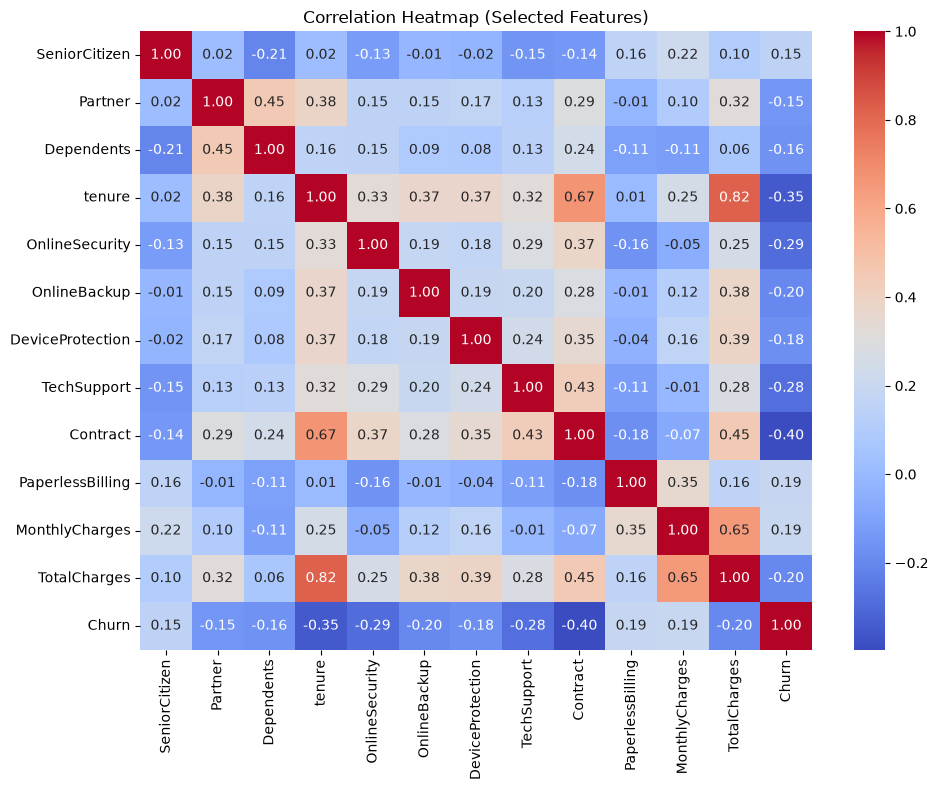

In [34]:
    plt.figure(figsize=(10, 8))
    corr_features = list(strong_corr.index) + ['Churn']
    sns.heatmap(df[corr_features].corr(), annot=True, fmt=".2f", cmap='coolwarm')
    plt.title("Correlation Heatmap (Selected Features)")
    plt.tight_layout()
    plt.show()

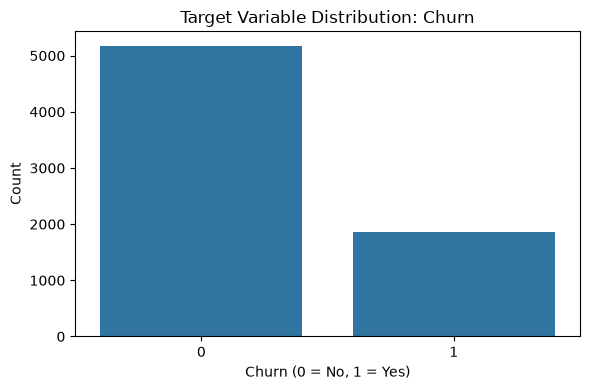

In [35]:
    plt.figure(figsize=(6, 4))
    sns.countplot(x=df['Churn'])
    plt.title("Target Variable Distribution: Churn")
    plt.xlabel("Churn (0 = No, 1 = Yes)")
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()

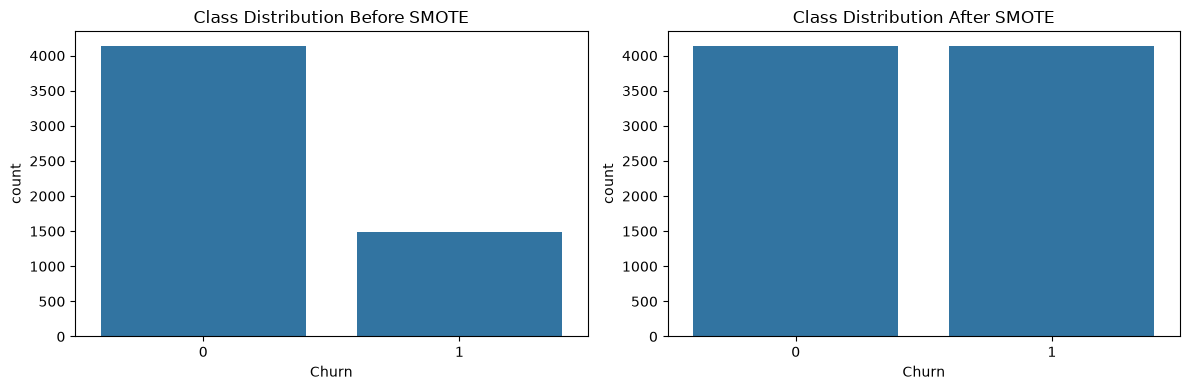

In [36]:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    
    sns.countplot(x=y_train, ax=axes[0])
    axes[0].set_title("Class Distribution Before SMOTE")
    axes[0].set_xlabel("Churn")
    
    smote = SMOTE(random_state=42)
    _, y_train_bal = smote.fit_resample(X_train, y_train)
    
    sns.countplot(x=y_train_bal, ax=axes[1])
    axes[1].set_title("Class Distribution After SMOTE")
    axes[1].set_xlabel("Churn")
    
    plt.tight_layout()
    plt.show()

In [38]:
base_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Random Forest':        RandomForestClassifier(n_estimators=100, random_state=42),
    'Decision Tree':        DecisionTreeClassifier(random_state=42),
    'KNN':                  KNeighborsClassifier(),
}


In [39]:
trained_models = {}
metrics_list = []

In [40]:
for name, estimator in base_models.items():
    pipe = ImbPipeline([
        ('poly', PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)),
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('model', estimator)
    ])
    pipe.fit(X_train, y_train)
    trained_models[name] = pipe
    
    preds = pipe.predict(X_test)
    metrics_list.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, preds),
        'Precision': precision_score(y_test, preds, average='weighted'),
        'Recall': recall_score(y_test, preds, average='weighted'),
        'F1 Score': f1_score(y_test, preds, average='weighted')
    })


In [43]:
results_df = pd.DataFrame(metrics_list)
print(results_df.to_string(index=False))


              Model  Accuracy  Precision   Recall  F1 Score
Logistic Regression  0.748048   0.802449 0.748048  0.761060
      Random Forest  0.773598   0.780384 0.773598  0.776548
      Decision Tree  0.722498   0.739761 0.722498  0.729432
                KNN  0.726757   0.767279 0.726757  0.738954
